# TinyStories: one exact packed-corpus epoch
Fresh random initialization. Each training next-character target is used once in shuffled non-overlapping chunks. Story boundaries are packed with blank lines; no special EOS token. Separate held-out stories. AdamW, batch 64, context 256; evaluation uses 20 random batches per split.

Imported v1 snapshot. Saved outputs describe the original Runpod run; paths below were adapted for this repository. Rerunning training replaces the local result files. Checkpoints are GitHub release assets and W&B model artifacts.


In [1]:
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'data').is_dir() and (p/'support').is_dir())
DATA_DIR = ROOT/'data/tinystories'
OUT_DIR = ROOT/'support/results/tinystories-one-epoch'
CHECKPOINT_DIR = ROOT/'support/checkpoints/tinystories-one-epoch'
OUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
import torch
print(torch.__version__, torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

/workspace/tinystories-gpt
2.8.0+cu128 True
NVIDIA RTX PRO 4000 Blackwell


## 1. TinyStories data and tokenizer
20,000 unique filtered stories: 18,000 train / 2,000 validation. Split by whole story before encoding. input.txt contains all selected stories; training uses train.txt and val.txt. Character-level model with 256-character context.

In [2]:
import torch
import torch.nn as nn
from torch.nn import functional as F

# hyperparameters
batch_size = 64 # how many independent sequences will we process in parallel?
block_size = 256 # what is the maximum context length for predictions?
max_iters = 5000
eval_interval = 500
learning_rate = 3e-4
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 384
n_head = 6
n_layer = 6
dropout = 0.2
# ------------

torch.manual_seed(1337)

# wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
with open(DATA_DIR/'input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

# here are all the unique characters that occur in this text
chars = sorted(list(set(text)))
vocab_size = len(chars)
# create a mapping from characters to integers
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode = lambda s: [stoi[c] for c in s] # encoder: take a string, output a list of integers
decode = lambda l: ''.join([itos[i] for i in l]) # decoder: take a list of integers, output a string

# Train and test splits
data = torch.tensor(encode(text), dtype=torch.long)
from pathlib import Path
train_data = torch.tensor(encode((DATA_DIR/'train.txt').read_text(encoding='utf-8')), dtype=torch.long)
val_data = torch.tensor(encode((DATA_DIR/'val.txt').read_text(encoding='utf-8')), dtype=torch.long)

# data loading
def get_batch(split):
    # generate a small batch of data of inputs x and targets y
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    x, y = x.to(device), y.to(device)
    return x, y

@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out



In [3]:
print(len(text), 'characters;', vocab_size, 'symbols')
print('Train chars:', len(train_data), 'Validation chars:', len(val_data))
print(text[:300])

17824201 characters; 80 symbols
Train chars: 16046878 Validation chars: 1777322
Once upon a time, there was a little girl named Lily. She loved to play outside and have fun with her friends. One day, Lily's mom told her that they were going to start planting a garden. Lily was so excited because she loved flowers and vegetables. Before they could start planting, Lily's mom said


## 2. Model
6 transformer layers, 6 attention heads, 384 embedding dimensions.

In [4]:
class Head(nn.Module):
    """ one head of self-attention """

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # input of size (batch, time-step, channels)
        # output of size (batch, time-step, head size)
        B,T,C = x.shape
        k = self.key(x)   # (B,T,hs)
        q = self.query(x) # (B,T,hs)
        # compute attention scores ("affinities")
        wei = q @ k.transpose(-2,-1) * k.shape[-1]**-0.5 # (B, T, hs) @ (B, hs, T) -> (B, T, T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf')) # (B, T, T)
        wei = F.softmax(wei, dim=-1) # (B, T, T)
        wei = self.dropout(wei)
        # perform the weighted aggregation of the values
        v = self.value(x) # (B,T,hs)
        out = wei @ v # (B, T, T) @ (B, T, hs) -> (B, T, hs)
        return out

class MultiHeadAttention(nn.Module):
    """ multiple heads of self-attention in parallel """

    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(head_size * num_heads, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

class FeedFoward(nn.Module):
    """ a simple linear layer followed by a non-linearity """

    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    """ Transformer block: communication followed by computation """

    def __init__(self, n_embd, n_head):
        # n_embd: embedding dimension, n_head: the number of heads we'd like
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedFoward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

class GPTLanguageModel(nn.Module):

    def __init__(self):
        super().__init__()
        # each token directly reads off the logits for the next token from a lookup table
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd) # final layer norm
        self.lm_head = nn.Linear(n_embd, vocab_size)

        # better init, not covered in the original GPT video, but important, will cover in followup video
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        # idx and targets are both (B,T) tensor of integers
        tok_emb = self.token_embedding_table(idx) # (B,T,C)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device)) # (T,C)
        x = tok_emb + pos_emb # (B,T,C)
        x = self.blocks(x) # (B,T,C)
        x = self.ln_f(x) # (B,T,C)
        logits = self.lm_head(x) # (B,T,vocab_size)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        # idx is (B, T) array of indices in the current context
        for _ in range(max_new_tokens):
            # crop idx to the last block_size tokens
            idx_cond = idx[:, -block_size:]
            # get the predictions
            logits, loss = self(idx_cond)
            # focus only on the last time step
            logits = logits[:, -1, :] # becomes (B, C)
            # apply softmax to get probabilities
            probs = F.softmax(logits, dim=-1) # (B, C)
            # sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
            # append sampled index to the running sequence
            idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
        return idx



In [5]:
model = GPTLanguageModel().to(device)
print(f'{sum(p.numel() for p in model.parameters()):,} trainable parameters')
print(f'Vocabulary: {vocab_size}; layers: {n_layer}; heads: {n_head}; embedding: {n_embd}; context: {block_size}')

10,800,464 trainable parameters
Vocabulary: 80; layers: 6; heads: 6; embedding: 384; context: 256


## 3. Train one epoch
About 980 updates. Partial last chunk is padded with loss ignored. Each training character target is used once. Evaluation windows do not update weights. Outputs: support/results/tinystories-one-epoch/.

In [6]:
import math, time, json
from pathlib import Path
torch.set_num_threads(4)
out=OUT_DIR; out.mkdir(exist_ok=True)
optimizer=torch.optim.AdamW(model.parameters(),lr=learning_rate)
count=math.ceil((len(train_data)-1)/block_size)
order=torch.randperm(count)
steps=math.ceil(count/batch_size)
history=[]
covered=0
began=time.time()
eval_iters=20
def record(step):
    losses=estimate_loss()
    row=dict(step=step,train=float(losses['train']),val=float(losses['val']),seconds=time.time()-began)
    history.append(row)
    (out/'loss.json').write_text(json.dumps(history,indent=2))
    print(row,flush=True)
record(0)
for step in range(steps):
    ids=order[step*batch_size:(step+1)*batch_size]
    x=torch.zeros((len(ids),block_size),dtype=torch.long)
    y=torch.full_like(x,-100)
    for row,idx in enumerate(ids.tolist()):
        start=idx*block_size
        n=min(block_size,len(train_data)-1-start)
        x[row,:n]=train_data[start:start+n]
        y[row,:n]=train_data[start+1:start+n+1]
        covered+=n
    _,loss=model(x.to(device),y.to(device))
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    if (step+1)%100==0 or step+1==steps:
        record(step+1)
        torch.save(dict(model=model.state_dict(),optimizer=optimizer.state_dict(),chars=chars,step=step+1,
            epoch=(step+1)/steps,config=dict(n_embd=n_embd,n_head=n_head,n_layer=n_layer,block_size=block_size,dropout=dropout)),CHECKPOINT_DIR/'checkpoint.pt')
assert covered==len(train_data)-1
summary=dict(epoch=1,updates=steps,targets_seen=covered,parameters=sum(p.numel() for p in model.parameters()),seconds=time.time()-began,final=history[-1])
(out/'summary.json').write_text(json.dumps(summary,indent=2))
print('ONE EPOCH COMPLETE',summary,flush=True)
model.eval()
with torch.no_grad():
    prompt='Once upon a time'
    ctx=torch.tensor([encode(prompt)],dtype=torch.long,device=device)
    sample=decode(model.generate(ctx,1000)[0].tolist())
(out/'sample.txt').write_text(sample)
print(sample)


{'step': 0, 'train': 4.409089088439941, 'val': 4.408660888671875, 'seconds': 1.8121347427368164}
{'step': 100, 'train': 2.3302764892578125, 'val': 2.3333942890167236, 'seconds': 15.365569114685059}
{'step': 200, 'train': 2.207282304763794, 'val': 2.212151288986206, 'seconds': 29.642899751663208}
{'step': 300, 'train': 1.9207127094268799, 'val': 1.91500723361969, 'seconds': 43.975914001464844}
{'step': 400, 'train': 1.5367374420166016, 'val': 1.526123285293579, 'seconds': 58.169870138168335}
{'step': 500, 'train': 1.346291422843933, 'val': 1.3437565565109253, 'seconds': 72.00776505470276}
{'step': 600, 'train': 1.2317324876785278, 'val': 1.2367761135101318, 'seconds': 85.90004634857178}
{'step': 700, 'train': 1.1578786373138428, 'val': 1.1579124927520752, 'seconds': 99.80001258850098}
{'step': 800, 'train': 1.1056492328643799, 'val': 1.1052144765853882, 'seconds': 113.65415668487549}
{'step': 900, 'train': 1.0522966384887695, 'val': 1.050446629524231, 'seconds': 127.4952347278595}
{'ste

## 4. Learning curves

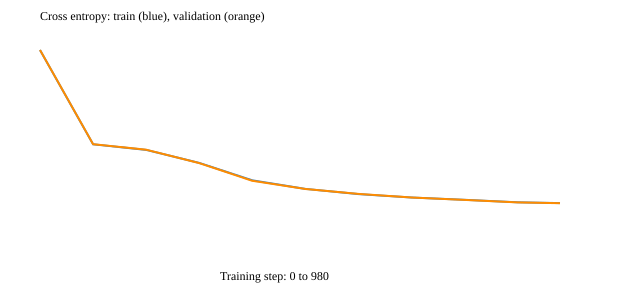

In [7]:
from IPython.display import SVG, display
xs=[r['step'] for r in history]
lines=[]
for key,color in [('train','steelblue'),('val','darkorange')]:
    points=' '.join(f'{40+520*x/max(xs):.1f},{250-200*r[key]/max(v[k] for v in history for k in ["train","val"]):.1f}' for x,r in zip(xs,history))
    lines.append(f'<polyline points="{points}" fill="none" stroke="{color}" stroke-width="2"/>')
display(SVG('<svg xmlns="http://www.w3.org/2000/svg" width="620" height="290"><rect width="620" height="290" fill="white"/><text x="40" y="20">Cross entropy: train (blue), validation (orange)</text>'+''.join(lines)+'<text x="220" y="280">Training step: 0 to 980</text></svg>'))

## 5. Generate
Change the prompt and rerun. This is a text completion model, not a chat assistant.

In [8]:
# Generation already runs at the end of the training cell.
print((OUT_DIR/'sample.txt').read_text())

Once upon a time, there was a bunny. One day, the help store. He slowly and until they seump and he had a bitten. He sees the clir on and pretends. He hopers and asks, "The kitty?" He sees he went to the birds. He was so splaying for Lily's impromises. He read he with held his houself, but he had tight the break, but it creaming to a big came. She hugger the bunny and a pot of the kitchen. "I will be with me jam." His dog asked. The open shared a special big and shouted to be on the tree. He said, "Thank you don't make a snide." AnSad Sara, there is scared. "You can ellong you catch and Ben. Ben are both you be dright to feel each." The catch little girl said, "The little boy is tree?" His dad came and the stopped by. They had lesso. They look at the place, They prettendow, but a small beack. The mom is so happy. They opened it the love it. They pick their hamme to get the pic tower. They were playing together and looked sun. They school asked him. They like to help the bunny flox the 

## Reload after a kernel restart
Run data and model definitions first, then use the following optional cell instead of training. Workspace retention depends on Runpod volume settings.

In [9]:
# Optional: reload this run after executing data and model definitions.
# ckpt=torch.load(CHECKPOINT_DIR/'checkpoint.pt',map_location=device,weights_only=False)
# model.load_state_dict(ckpt['model'])